# Phase 2 — xG Model: Feature Engineering & Initial Training

**Goal:** Build a gradient-boosted expected goals model from shot events.

**Data contract (from Phase 1):**
- Filter: `period <= 4` (exclude shootout)
- Filter: `event_type IN ('shot-on-goal', 'goal', 'missed-shot')` (exclude blocked shots)
- Result: ~565k clean unblocked non-shootout shots

**Features (this iteration):**
- Tier 1 (geometric): distance to net, angle to net
- Tier 2 (shot context): shot type
- Tier 3 (sequence): is_rebound, time_since_prior_shot
- Deferred: strength state (requires shift-join), rush flag (requires full play-by-play)

**Target:** binary `is_goal` (1 if event_type == 'goal', 0 otherwise)

## 1 — Load & Filter Raw Shots

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Update this path to your database ---
DB_PATH = "data/hockey_stats.db"

conn = sqlite3.connect(DB_PATH)

# Apply both filter rules from Phase 1
query = """
SELECT
    se.game_id,
    se.event_id,
    se.period,
    se.time_in_period,
    se.event_type,
    se.team_id,
    se.shooting_player_id,
    se.goalie_id,
    se.x_coord,
    se.y_coord,
    se.zone_code,
    se.shot_type,
    g.season,
    g.game_date,
    g.home_team_abbrev,
    g.away_team_abbrev
FROM shot_events se
JOIN games g ON se.game_id = g.id
WHERE se.period <= 4
  AND se.event_type IN ('shot-on-goal', 'goal', 'missed-shot')
ORDER BY se.game_id, se.period, se.time_in_period
"""

df = pd.read_sql(query, conn)
print(f"Clean shots loaded: {len(df):,}")
print(f"Seasons: {sorted(df['season'].unique())}")
print(f"Event types: {df['event_type'].value_counts().to_dict()}")
print(f"Goal rate: {(df['event_type'] == 'goal').mean():.3%}")

Clean shots loaded: 566,545
Seasons: [np.int64(20212022), np.int64(20222023), np.int64(20232024), np.int64(20242025), np.int64(20252026)]
Event types: {'shot-on-goal': 351286, 'missed-shot': 174788, 'goal': 40471}
Goal rate: 7.143%


## 2 — Coordinate Normalization

The NHL coordinate system has nets at approximately x = -89 and x = +89.
Which net a team attacks depends on the period — teams switch ends each period.
We need all shots oriented toward the same net (x = 89) so distance and angle
calculations are consistent.

**Approach:** For each team in each game in each period, compute the mean
x-coordinate of their shots. If the mean is negative, that team is attacking
the x = -89 net in that period, so we flip both x and y. This is self-correcting
regardless of arena convention — the data tells us which direction each team is
shooting, rather than us guessing from period number.

The simpler `if x < 0: flip` heuristic (used in `shot_heatmap.py`) works for
~98% of shots, but misclassifies shots taken from behind the attacking blue
line or from the neutral zone. The empirical approach eliminates those edge cases.

In [2]:
# Empirical normalization: compute mean x per team per game per period
# If mean is negative, that team is attacking the -89 net → flip

# Step 1: compute the mean x-coordinate for each team-game-period group
attack_direction = df.groupby(["game_id", "team_id", "period"])["x_coord"].mean()
attack_direction.name = "mean_x"
attack_direction = attack_direction.reset_index()

# Step 2: merge back onto every shot
df = df.merge(attack_direction, on=["game_id", "team_id", "period"], how="left")

# Step 3: if the team's mean x is negative in this period, flip
flip_mask = df["mean_x"] < 0
print(f"Shots to flip: {flip_mask.sum():,} ({flip_mask.mean():.1%})")

df["x_norm"] = np.where(flip_mask, -df["x_coord"], df["x_coord"])
df["y_norm"] = np.where(flip_mask, -df["y_coord"], df["y_coord"])

# Compare against the naive approach to see how many shots differ
naive_flip = df["x_coord"] < 0
disagree = flip_mask != naive_flip
print(f"Shots where empirical disagrees with naive (x<0): {disagree.sum():,} ({disagree.mean():.2%})")

# Clean up the temporary column
df.drop(columns=["mean_x"], inplace=True)

# Sanity check: after normalization, vast majority should be in offensive zone
print(f"\nPost-normalization x_norm > 25 (offensive zone): {(df['x_norm'] > 25).mean():.1%}")
print(f"x_norm range: [{df['x_norm'].min():.1f}, {df['x_norm'].max():.1f}]")
print(f"y_norm range: [{df['y_norm'].min():.1f}, {df['y_norm'].max():.1f}]")

Shots to flip: 284,703 (50.3%)
Shots where empirical disagrees with naive (x<0): 12,912 (2.28%)

Post-normalization x_norm > 25 (offensive zone): 95.8%
x_norm range: [-99.0, 99.0]
y_norm range: [-42.0, 42.0]


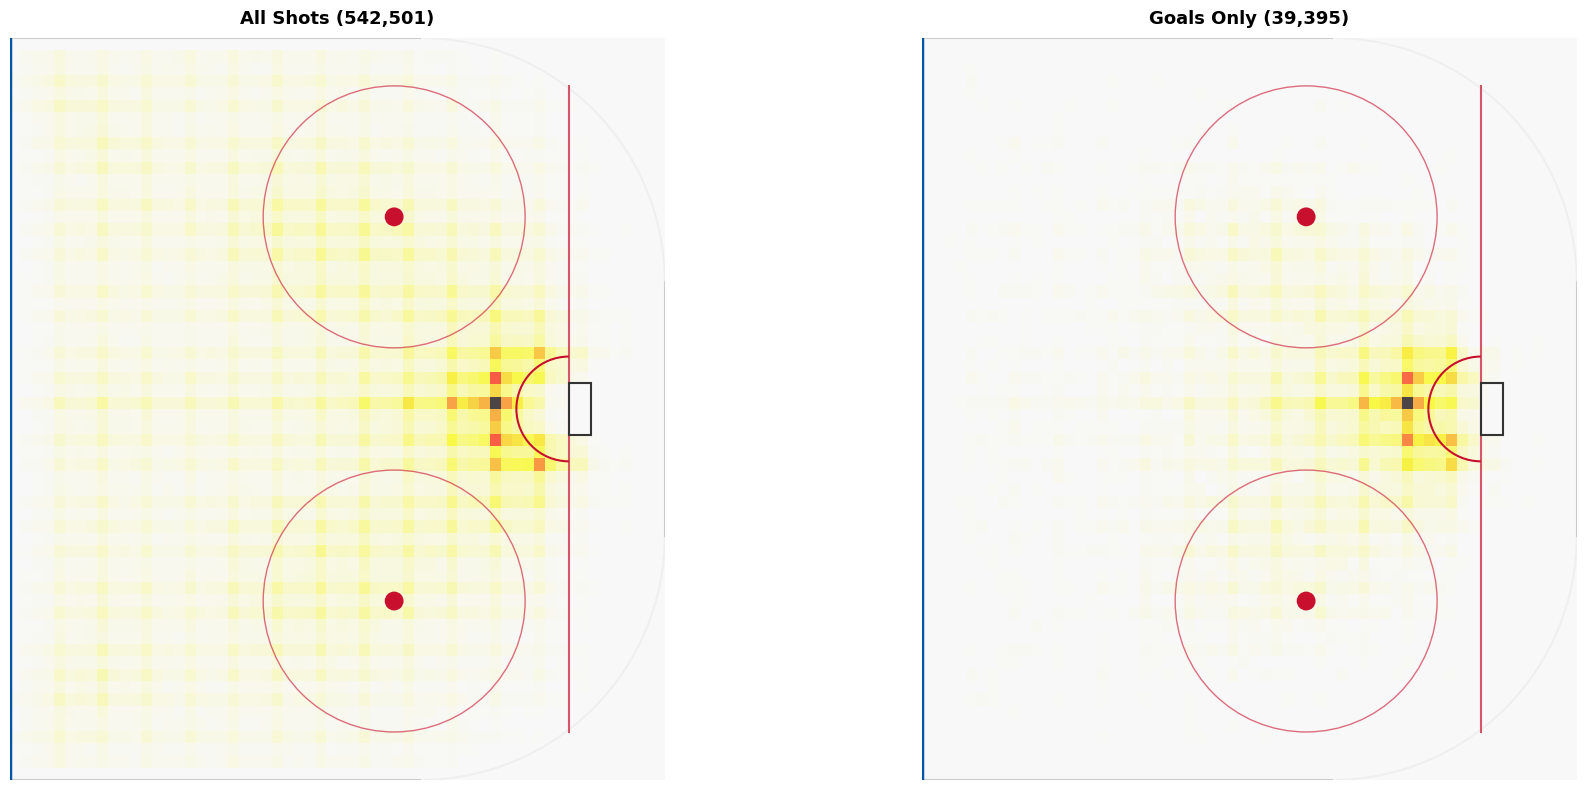

In [3]:
# Visual confirmation: KDE heatmap of all normalized shot locations
# Reuse draw_half_rink and _draw_kde from shot_heatmap.py
import sys
sys.path.insert(0, '.')  # adjust if notebook isn't in project root
from src.viz.shot_heatmap import draw_half_rink, _draw_kde

# # Filter to offensive zone for the KDE (same as heatmap code does)
# ozone = df[df["x_norm"] > 25]
# x_oz = ozone["x_norm"].values
# y_oz = ozone["y_norm"].values

# fig, axes = plt.subplots(1, 2, figsize=(20, 8), facecolor="#f5f5f5")
# fig.suptitle("Normalized Shot Locations — All Shots (566k)",
#              fontsize=16, fontweight="bold", y=0.97)

# # Left panel: all shots
# ax = axes[0]
# draw_half_rink(ax)
# _draw_kde(ax, x_oz, y_oz)
# ax.set_title(f"All Shots ({len(ozone):,} in offensive zone)",
#              fontsize=13, fontweight="bold", pad=10)

# # Right panel: goals only
# ax = axes[1]
# draw_half_rink(ax)
# goals_oz = df[(df["x_norm"] > 25) & (df["event_type"] == "goal")]
# if len(goals_oz) > 2:
#     _draw_kde(ax, goals_oz["x_norm"].values, goals_oz["y_norm"].values)
# ax.set_title(f"Goals Only ({len(goals_oz):,})",
#              fontsize=13, fontweight="bold", pad=10)

# plt.tight_layout(rect=[0, 0, 1, 0.93])
# plt.show()

# # Also report how many shots are outside offensive zone
# outside_oz = len(df) - len(ozone)
# print(f"\nShots outside offensive zone (x_norm <= 25): {outside_oz:,} ({outside_oz/len(df):.1%})")

# Quick alternative — instant regardless of data size
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for ax, data, title in [
    (axes[0], df[df["x_norm"] > 25], "All Shots"),
    (axes[1], df[(df["x_norm"] > 25) & (df["event_type"] == "goal")], "Goals Only"),
]:
    draw_half_rink(ax)
    ax.hist2d(data["x_norm"], data["y_norm"],
              bins=[60, 60], range=[[25, 100], [-42.5, 42.5]],
              cmap="hot_r", alpha=0.7, zorder=1)
    ax.set_title(f"{title} ({len(data):,})", fontsize=13, fontweight="bold", pad=10)

plt.tight_layout()
plt.show()

## 3 — Geometric Features: Distance and Angle

- **Distance:** Euclidean distance from shot location to center of net (89, 0)
- **Angle:** Angle from shot location to center of net. 0° = straight on, 90° = on the goal line

These two features alone carry the bulk of xG signal.

In [4]:
# Net location
NET_X = 89.0
NET_Y = 0.0

# Distance to net
df["distance"] = np.sqrt((df["x_norm"] - NET_X)**2 + (df["y_norm"] - NET_Y)**2)

# Angle to net: 0 = dead center, increases as you move to the side
# Using absolute angle so left/right are symmetric
df["angle"] = np.abs(np.degrees(np.arctan2(df["y_norm"] - NET_Y, NET_X - df["x_norm"])))

print("Distance stats:")
print(df["distance"].describe())
print(f"\nAngle stats:")
print(df["angle"].describe())

Distance stats:
count    566545.000000
mean         35.408450
std          24.977252
min           0.000000
25%          16.552945
50%          32.202484
75%          48.414874
max         189.169236
Name: distance, dtype: float64

Angle stats:
count    566545.000000
mean         32.199920
std          22.065388
min           0.000000
25%          15.124007
50%          29.859016
75%          45.000000
max         180.000000
Name: angle, dtype: float64


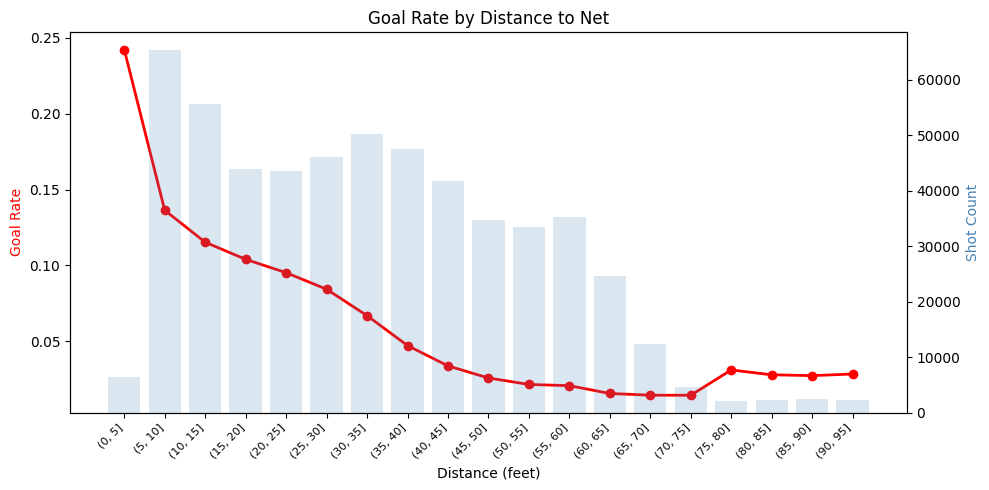

In [5]:
# Sanity check: goal rate by distance bin
# Should decrease monotonically — closer shots score more
df["is_goal"] = (df["event_type"] == "goal").astype(int)

df["dist_bin"] = pd.cut(df["distance"], bins=range(0, 100, 5))
dist_rates = df.groupby("dist_bin", observed=True).agg(
    goal_rate=("is_goal", "mean"),
    count=("is_goal", "count")
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

x_pos = range(len(dist_rates))
ax2.bar(x_pos, dist_rates["count"], alpha=0.2, color="steelblue", label="shot count")
ax1.plot(x_pos, dist_rates["goal_rate"], "o-", color="red", lw=2, label="goal rate")

ax1.set_xticks(x_pos)
ax1.set_xticklabels([str(b) for b in dist_rates["dist_bin"]], rotation=45, ha="right", fontsize=8)
ax1.set_ylabel("Goal Rate", color="red")
ax2.set_ylabel("Shot Count", color="steelblue")
ax1.set_title("Goal Rate by Distance to Net")
ax1.set_xlabel("Distance (feet)")
fig.tight_layout()
plt.show()

# Drop the temporary bin column
df.drop(columns=["dist_bin"], inplace=True)

In [ ]:
# Sanity check: goal rate by angle bin
# Should decrease as angle increases — straight-on shots score more

df["angle_bin"] = pd.cut(df["angle"], bins=range(0, 95, 5))
angle_rates = df.groupby("angle_bin", observed=True).agg(
    goal_rate=("is_goal", "mean"),
    count=("is_goal", "count")
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

x_pos = range(len(angle_rates))
ax2.bar(x_pos, angle_rates["count"], alpha=0.2, color="steelblue", label="shot count")
ax1.plot(x_pos, angle_rates["goal_rate"], "o-", color="red", lw=2, label="goal rate")

ax1.set_xticks(x_pos)
ax1.set_xticklabels([str(b) for b in angle_rates["angle_bin"]], rotation=45, ha="right", fontsize=8)
ax1.set_ylabel("Goal Rate", color="red")
ax2.set_ylabel("Shot Count", color="steelblue")
ax1.set_title("Goal Rate by Shot Angle")
ax1.set_xlabel("Angle (degrees)")
fig.tight_layout()
plt.show()

df.drop(columns=["angle_bin"], inplace=True)

## 4 — Shot Type Feature

Shot type is a strong categorical feature. Deflections and tip-ins score at
roughly double the rate of wrist shots from the same location. LightGBM can
handle categoricals natively, so we encode as integer category codes.

In [6]:
# Explore shot types and their goal rates
shot_type_stats = df.groupby("shot_type").agg(
    count=("is_goal", "count"),
    goals=("is_goal", "sum"),
    goal_rate=("is_goal", "mean")
).sort_values("count", ascending=False)

print("Shot Type Breakdown:")
print(shot_type_stats.to_string())
print(f"\nNULL shot_type: {df['shot_type'].isna().sum():,}")

Shot Type Breakdown:
               count  goals  goal_rate
shot_type                             
wrist         289928  19092   0.065851
snap           99062   8635   0.087168
slap           69000   3426   0.049652
tip-in         48058   3944   0.082068
backhand       41060   3529   0.085947
deflected      11299   1085   0.096026
wrap-around     4341    226   0.052062
poke            1692    212   0.125296
bat             1687    201   0.119146
between-legs     291     24   0.082474
cradle            35      5   0.142857

NULL shot_type: 92


In [9]:
# Encode shot type as categorical integer codes for LightGBM
# NaN shot types get code -1 (LightGBM handles this natively)
df["shot_type_cat"] = df["shot_type"].astype("category")
df["shot_type_code"] = df["shot_type_cat"].cat.codes  # -1 for NaN


# Store the mapping for later reference
shot_type_mapping = dict(enumerate(df["shot_type_cat"].cat.categories))
print("Shot type code mapping:")
for code, name in shot_type_mapping.items():
    print(f"  {code}: {name}")

print(df["shot_type"].value_counts(dropna=False))

Shot type code mapping:
  0: backhand
  1: bat
  2: between-legs
  3: cradle
  4: deflected
  5: poke
  6: slap
  7: snap
  8: tip-in
  9: wrap-around
  10: wrist
shot_type
wrist           289928
snap             99062
slap             69000
tip-in           48058
backhand         41060
deflected        11299
wrap-around       4341
poke              1692
bat               1687
between-legs       291
NaN                 92
cradle              35
Name: count, dtype: int64


## 5 — Sequence Features: Rebound Flag & Time Since Prior Shot

A **rebound** is a shot that follows another shot by the same team within ~3 seconds.
Rebound shots score at roughly 20-25% — 3-4x the base rate — because the goalie
is still recovering.

Since we only have shot events (not full play-by-play), we compute these relative
to the prior shot in the same game, regardless of team. Then we check if the prior
shot was from the same team.

In [10]:
# Convert time_in_period to total elapsed seconds for delta calculation
# time_in_period is stored as "MM:SS" string

def time_str_to_seconds(t):
    """Convert 'MM:SS' to total seconds elapsed in period."""
    if pd.isna(t):
        return np.nan
    parts = str(t).split(":")
    return int(parts[0]) * 60 + int(parts[1])

df["time_seconds"] = df["time_in_period"].apply(time_str_to_seconds)

# Compute total game seconds (for cross-period deltas)
# Period 1: 0-1200s, Period 2: 1200-2400s, Period 3: 2400-3600s, OT: 3600+
PERIOD_LENGTH = 1200  # 20 minutes
df["game_seconds"] = (df["period"] - 1) * PERIOD_LENGTH + df["time_seconds"]

print(f"game_seconds range: [{df['game_seconds'].min()}, {df['game_seconds'].max()}]")
print(f"NaN count: {df['game_seconds'].isna().sum()}")

game_seconds range: [1, 3900]
NaN count: 0


In [11]:
# Sort by game and time, then compute lag features within each game
df = df.sort_values(["game_id", "game_seconds"]).reset_index(drop=True)

# Prior shot in the same game (regardless of team)
df["prev_game_id"] = df.groupby("game_id")["game_id"].shift(1)
df["prev_team_id"] = df.groupby("game_id")["team_id"].shift(1)
df["prev_game_seconds"] = df.groupby("game_id")["game_seconds"].shift(1)

# Time since prior shot (in seconds)
df["time_since_prev_shot"] = df["game_seconds"] - df["prev_game_seconds"]

# Rebound: same team, within 3 seconds
REBOUND_THRESHOLD = 3.0  # seconds
df["is_rebound"] = (
    (df["team_id"] == df["prev_team_id"]) &
    (df["time_since_prev_shot"] <= REBOUND_THRESHOLD) &
    (df["time_since_prev_shot"] > 0)  # exclude exact same timestamp edge cases
).astype(int)

# First shot in each game has no prior — set NaN for time, 0 for rebound
first_shot_mask = df["prev_game_id"].isna()
df.loc[first_shot_mask, "is_rebound"] = 0
df.loc[first_shot_mask, "time_since_prev_shot"] = np.nan  # LightGBM handles NaN

print(f"Rebound shots: {df['is_rebound'].sum():,} ({df['is_rebound'].mean():.1%})")
print(f"\nGoal rate on rebounds: {df[df['is_rebound'] == 1]['is_goal'].mean():.1%}")
print(f"Goal rate on non-rebounds: {df[df['is_rebound'] == 0]['is_goal'].mean():.1%}")
print(f"\ntime_since_prev_shot stats (seconds):")
print(df["time_since_prev_shot"].describe())

Rebound shots: 41,421 (7.3%)

Goal rate on rebounds: 12.6%
Goal rate on non-rebounds: 6.7%

time_since_prev_shot stats (seconds):
count    559985.000000
mean         41.741898
std          41.919286
min           0.000000
25%          12.000000
50%          29.000000
75%          58.000000
max         588.000000
Name: time_since_prev_shot, dtype: float64


In [12]:
# Sanity check: rebound goal rate should be dramatically higher (~20%+ vs ~7%)
# If it's not, something is wrong with the lag calculation

rebound_check = df.groupby("is_rebound").agg(
    count=("is_goal", "count"),
    goals=("is_goal", "sum"),
    goal_rate=("is_goal", "mean")
)
print("Rebound vs Non-Rebound:")
print(rebound_check)

Rebound vs Non-Rebound:
             count  goals  goal_rate
is_rebound                          
0           525124  35235   0.067098
1            41421   5236   0.126409


## 6 — Assemble Feature Matrix

Collect all features into the training matrix. For this first iteration:

| Feature | Type | Source |
|---|---|---|
| `distance` | float | Euclidean distance to net |
| `angle` | float | Absolute angle to net center |
| `shot_type_code` | categorical int | Encoded shot type |
| `is_rebound` | binary int | Same-team shot within 3s |
| `time_since_prev_shot` | float | Seconds since prior shot (NaN for first in game) |

In [13]:
FEATURE_COLS = ["distance", "angle", "shot_type_code", "is_rebound", "time_since_prev_shot"]
TARGET_COL = "is_goal"

# Check for any unexpected NaNs in features (time_since_prev_shot NaN is expected)
print("NaN counts in features:")
for col in FEATURE_COLS:
    nan_count = df[col].isna().sum()
    print(f"  {col}: {nan_count:,} ({nan_count/len(df):.2%})")

print(f"\nTotal rows: {len(df):,}")
print(f"Target distribution: {df[TARGET_COL].value_counts().to_dict()}")

NaN counts in features:
  distance: 0 (0.00%)
  angle: 0 (0.00%)
  shot_type_code: 0 (0.00%)
  is_rebound: 0 (0.00%)
  time_since_prev_shot: 6,560 (1.16%)

Total rows: 566,545
Target distribution: {0: 526074, 1: 40471}


## 7 — Temporal Train/Test Split

**No random shuffle.** Train on earlier seasons, test on the most recent.
This simulates the real use case: train on history, predict the future.
Random splits would leak future information into training.

In [14]:
# See what seasons we have
print("Shots per season:")
print(df.groupby("season")["is_goal"].agg(["count", "mean"]).to_string())

# Split: train on all seasons except the most recent, test on the most recent
test_season = df["season"].max()
train_seasons = sorted(df["season"].unique())[:-1]

train_mask = df["season"].isin(train_seasons)
test_mask = df["season"] == test_season

X_train = df.loc[train_mask, FEATURE_COLS]
y_train = df.loc[train_mask, TARGET_COL]
X_test = df.loc[test_mask, FEATURE_COLS]
y_test = df.loc[test_mask, TARGET_COL]

print(f"\nTrain: seasons {train_seasons} — {len(X_train):,} shots")
print(f"Test:  season {test_season} — {len(X_test):,} shots")
print(f"Train goal rate: {y_train.mean():.3%}")
print(f"Test goal rate:  {y_test.mean():.3%}")

Shots per season:
           count      mean
season                    
20212022  113290  0.071939
20222023  114088  0.072295
20232024  114839  0.070412
20242025  112237  0.070396
20252026  112091  0.072138

Train: seasons [np.int64(20212022), np.int64(20222023), np.int64(20232024), np.int64(20242025)] — 454,454 shots
Test:  season 20252026 — 112,091 shots
Train goal rate: 7.126%
Test goal rate:  7.214%


## 8 — Train LightGBM Model

Binary classifier with log-loss objective. `shot_type_code` is passed as a
categorical feature so LightGBM uses optimal splits rather than treating
the integer codes as ordinal.

In [15]:
import lightgbm as lgb
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

# Create LightGBM datasets
# Specify shot_type_code as categorical
categorical_features = ["shot_type_code"]

dtrain = lgb.Dataset(
    X_train, label=y_train,
    categorical_feature=categorical_features,
    free_raw_data=False
)
dtest = lgb.Dataset(
    X_test, label=y_test,
    categorical_feature=categorical_features,
    reference=dtrain,
    free_raw_data=False
)

# Conservative hyperparameters for a first pass — tune later
params = {
    "objective": "binary",
    "metric": "binary_logloss",
    "boosting_type": "gbdt",
    "num_leaves": 31,
    "max_depth": 6,
    "learning_rate": 0.05,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 5,
    "min_child_samples": 100,  # conservative — avoids overfitting on rare shot types
    "verbose": -1,
    "seed": 42,
}

# Train with early stopping
model = lgb.train(
    params,
    dtrain,
    num_boost_round=1000,
    valid_sets=[dtrain, dtest],
    valid_names=["train", "test"],
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(100)
    ]
)

print(f"\nBest iteration: {model.best_iteration}")

Training until validation scores don't improve for 50 rounds
[100]	train's binary_logloss: 0.230505	test's binary_logloss: 0.233514
[200]	train's binary_logloss: 0.229276	test's binary_logloss: 0.233132
[300]	train's binary_logloss: 0.228377	test's binary_logloss: 0.233114
Early stopping, best iteration is:
[290]	train's binary_logloss: 0.228454	test's binary_logloss: 0.233089

Best iteration: 290


## 9 — Evaluate Model Performance

In [16]:
# Predict on test set
y_pred = model.predict(X_test, num_iteration=model.best_iteration)

# Scoring
ll = log_loss(y_test, y_pred)
brier = brier_score_loss(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred)

# Baseline: predict league-average goal rate for every shot
baseline_pred = np.full_like(y_pred, y_train.mean())
ll_baseline = log_loss(y_test, baseline_pred)
brier_baseline = brier_score_loss(y_test, baseline_pred)

print("=== Test Set Performance ===")
print(f"Log-loss:     {ll:.4f}  (baseline: {ll_baseline:.4f})")
print(f"Brier score:  {brier:.4f}  (baseline: {brier_baseline:.4f})")
print(f"AUC-ROC:      {auc:.4f}")
print(f"\nLog-loss improvement over baseline: {(1 - ll/ll_baseline):.1%}")

=== Test Set Performance ===
Log-loss:     0.2331  (baseline: 0.2591)
Brier score:  0.0628  (baseline: 0.0669)
AUC-ROC:      0.7399

Log-loss improvement over baseline: 10.1%


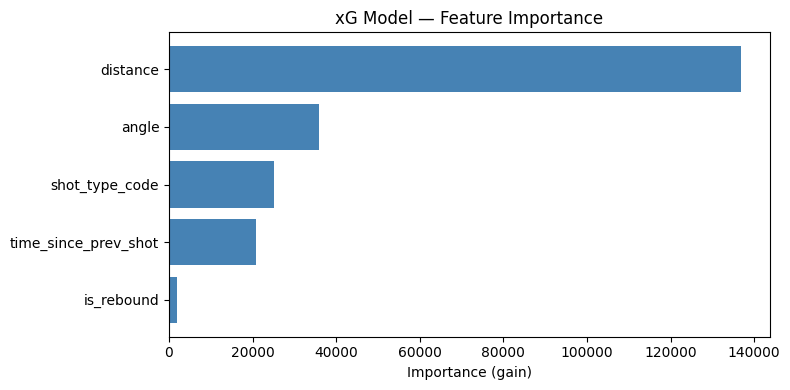

             feature    importance
            distance 136879.773816
               angle  35886.427824
      shot_type_code  25140.379242
time_since_prev_shot  20770.999238
          is_rebound   1843.008268


In [17]:
# Feature importance
importance = pd.DataFrame({
    "feature": FEATURE_COLS,
    "importance": model.feature_importance(importance_type="gain")
}).sort_values("importance", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importance["feature"], importance["importance"], color="steelblue")
ax.set_xlabel("Importance (gain)")
ax.set_title("xG Model — Feature Importance")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print(importance.to_string(index=False))

## 10 — Calibration Check

The model outputs probabilities. Are they calibrated?
If the model says 10% for a group of shots, ~10% should actually be goals.

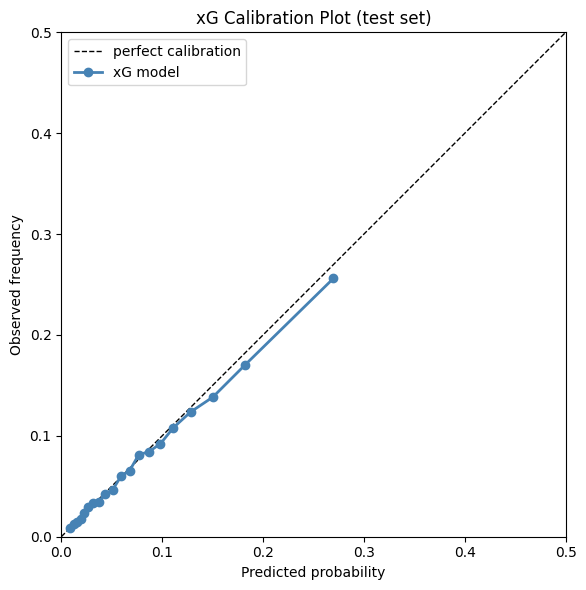

In [18]:
# Calibration plot
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(y_test, y_pred, n_bins=20, strategy="quantile")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.plot(prob_pred, prob_true, "o-", color="steelblue", lw=2, label="xG model")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Observed frequency")
ax.set_title("xG Calibration Plot (test set)")
ax.legend()
ax.set_xlim(0, 0.5)  # most xG values are < 0.5
ax.set_ylim(0, 0.5)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 11 — Per-Game Team xG Aggregation

The downstream pipeline needs **team-level xG per game**, not per-shot.
Sum the per-shot xG for each team in each game. This is what we'll
correlate against MoneyPuck.

Per-game team xG stats:
               xGF        shots        goals
count  2624.000000  2624.000000  2624.000000
mean      3.200454    42.717607     3.081555
std       0.855097     8.841678     1.721403
min       1.101435    18.000000     0.000000
25%       2.577795    36.000000     2.000000
50%       3.126988    42.000000     3.000000
75%       3.709246    48.000000     4.000000
max       7.129320    75.000000    10.000000


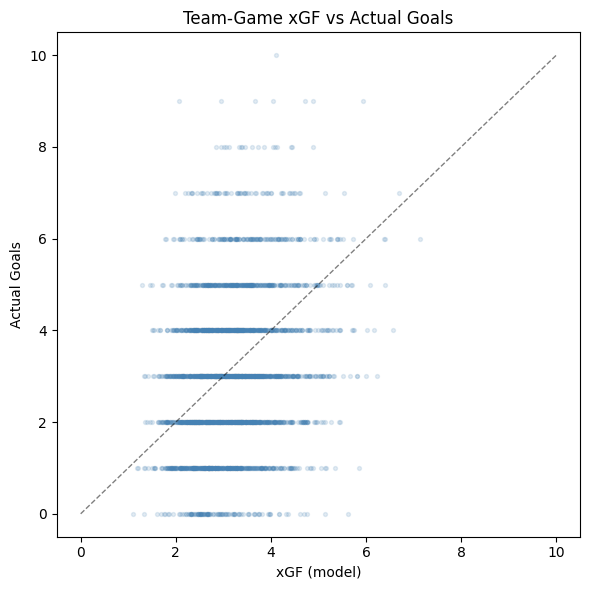


Correlation (xGF vs actual goals): r = 0.223
Season-level correlation: r = 0.786


In [20]:
# Score every shot in the test set
df_test = df[test_mask].copy()
df_test["xG"] = y_pred

# Aggregate: xG for and against per team per game
team_game_xg = df_test.groupby(["game_id", "team_id"]).agg(
    xGF=("xG", "sum"),
    shots=("xG", "count"),
    goals=("is_goal", "sum")
).reset_index()

print("Per-game team xG stats:")
print(team_game_xg[["xGF", "shots", "goals"]].describe())

# Quick sanity: xGF vs actual goals scatter
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(team_game_xg["xGF"], team_game_xg["goals"], s=8, alpha=0.15, color="steelblue")
max_val = max(team_game_xg["xGF"].max(), team_game_xg["goals"].max())
ax.plot([0, max_val], [0, max_val], "k--", lw=1, alpha=0.5)
ax.set_xlabel("xGF (model)")
ax.set_ylabel("Actual Goals")
ax.set_title("Team-Game xGF vs Actual Goals")
plt.tight_layout()
plt.show()

# Correlation
r = team_game_xg["xGF"].corr(team_game_xg["goals"])
print(f"\nCorrelation (xGF vs actual goals): r = {r:.3f}")

season_totals = team_game_xg.groupby("team_id").agg(
    total_xGF=("xGF", "sum"),
    total_goals=("goals", "sum")
).reset_index()

r_season = season_totals["total_xGF"].corr(season_totals["total_goals"])
print(f"Season-level correlation: r = {r_season:.3f}")

## 12 — Spot-Check: Known Game

Pick a specific game you can verify by eye. Check that per-shot xG values
are sensible (high for close-in chances, low for blue-line shots).

In [21]:
# Pick a game from the test set — adjust game_id as needed
# Try the most recent game, or pick a specific one you know
sample_game_id = df_test["game_id"].iloc[0]
game_shots = df_test[df_test["game_id"] == sample_game_id].copy()

print(f"Game {sample_game_id}:")
print(f"  Date: {game_shots['game_date'].iloc[0]}")
print(f"  {game_shots['away_team_abbrev'].iloc[0]} @ {game_shots['home_team_abbrev'].iloc[0]}")
print(f"  Total shots: {len(game_shots)}")
print()

# Show each shot with its xG
cols_to_show = ["period", "time_in_period", "event_type", "shot_type",
                "distance", "angle", "is_rebound", "xG"]
print(game_shots[cols_to_show].to_string(index=False, float_format="{:.3f}".format))

Game 2025020001:
  Date: 2025-10-07
  CHI @ FLA
  Total shots: 82

 period time_in_period   event_type shot_type  distance   angle  is_rebound    xG
      1          01:16 shot-on-goal     wrist    38.013  35.362           0 0.040
      1          01:35 shot-on-goal      slap    59.135  18.741           0 0.035
      1          01:44  missed-shot      snap    44.688  40.462           0 0.026
      1          02:02 shot-on-goal      snap    63.285  31.430           0 0.011
      1          02:52 shot-on-goal      snap    68.096  29.954           0 0.015
      1          03:34 shot-on-goal      slap    41.773  42.089           0 0.048
      1          03:38  missed-shot     wrist    43.681  15.945           0 0.025
      1          04:06 shot-on-goal     wrist    13.454  41.987           0 0.125
      1          04:41  missed-shot    tip-in     8.062  29.745           0 0.133
      1          04:42 shot-on-goal     wrist     6.000  90.000           1 0.032
      1          04:52  missed-

## 13 — Logistic Regression Baseline (Optional)

Quick baseline to see how much the gradient boosting adds over a linear model.
If LightGBM only improves by a tiny margin, the non-linear interactions
aren't adding much with the current feature set.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Logistic regression needs imputed NaN and scaled features
X_train_lr = X_train.copy()
X_test_lr = X_test.copy()

# Fill NaN in time_since_prev_shot with median
median_time = X_train_lr["time_since_prev_shot"].median()
X_train_lr["time_since_prev_shot"] = X_train_lr["time_since_prev_shot"].fillna(median_time)
X_test_lr["time_since_prev_shot"] = X_test_lr["time_since_prev_shot"].fillna(median_time)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_lr)
X_test_scaled = scaler.transform(X_test_lr)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict_proba(X_test_scaled)[:, 1]
ll_lr = log_loss(y_test, y_pred_lr)
auc_lr = roc_auc_score(y_test, y_pred_lr)

print("=== Model Comparison ===")
print(f"{'Model':<20} {'Log-loss':>10} {'AUC':>8}")
print(f"{'Baseline (mean)':<20} {ll_baseline:>10.4f} {'N/A':>8}")
print(f"{'Logistic Regression':<20} {ll_lr:>10.4f} {auc_lr:>8.4f}")
print(f"{'LightGBM':<20} {ll:>10.4f} {auc:>8.4f}")
print(f"\nLightGBM improvement over LogReg: {(1 - ll/ll_lr):.1%}")

=== Model Comparison ===
Model                  Log-loss      AUC
Baseline (mean)          0.2591      N/A
Logistic Regression      0.2472   0.6920
LightGBM                 0.2331   0.7399

LightGBM improvement over LogReg: 5.7%


## Next Steps

Once this notebook looks good:

1. **Refactor** the feature engineering + model into `src/models/deterministic/xg.py`
2. **Write** the training pipeline in `src/pipelines/train_xg.py`
3. **Validate** against MoneyPuck per-game xG totals (target r > 0.9)
4. **Pickle** the trained model to `output/models/xg_lgbm_v1_YYYY-YYYY.pkl`

Future iterations:
- Add strength state (requires joining shifts table to shot events)
- Add rush flag (requires full play-by-play events, not just shots)
- Hyperparameter tuning
- Period as a feature
- Behind-the-net shots (x_norm > 89) — currently included, may want special handling